# Community Detection on the Karate Club Graph using Spectral Modularity

DSC212: Graph Theory, Research Assignment

Name: Aaron Jimmy  
Roll No: IMS25002  
Date: November 2026

## 1. About the data

Zachary's karate club network was recorded by Wayne Zachary in the early 1970s. It has 34 members (nodes) and 78 ties (edges), where an edge means that two members spent time together often outside of class. While he was observing, the club broke into two groups after an argument between the instructor Mr. Hi (node 0) and the administrator John A. (node 33). Since the ties were recorded before the break up, we can check if the graph structure alone is enough to predict how the club split. Only one member, node 8, is known to have joined the side that the friendships did not suggest.

The copy of the graph in NetworkX stores edge weights. The assignment treats the network as unweighted, so the weights are ignored in the code and the graph has exactly 78 edges.

## 2. Method

Let A be the adjacency matrix, k the degree vector and 2m the sum of all degrees. The modularity matrix is

$$B = A - \frac{k k^T}{2m}$$

Here $k_i k_j / 2m$ is the number of edges expected between i and j if the edges were placed at random with the same degrees. For a split given by a vector s with entries +1 or -1, the modularity is

$$Q = \frac{1}{4m} s^T B s$$

Trying all 2^n choices of s is not possible, so s is relaxed to any unit vector. The best unit vector is the eigenvector of B with the largest eigenvalue (Rayleigh-Ritz), and nodes are put in group 1 or group 2 by the sign of their entry in that eigenvector.

To get more than two communities the same step is repeated on each group C using the block B(C) of B:

1. find the largest eigenvalue and its eigenvector for B(C)
2. if the eigenvalue is not positive (or the gain s^T B(C) s is not positive) the group is not split
3. otherwise split by sign and repeat on both halves

This follows Newman (2006). After every split I calculated degree, betweenness, closeness and clustering for each node with the NetworkX functions. They are calculated on the graph with the edges between different communities removed, so the values show where a node stands inside its own group (on the full graph they would not change from split to split). Closeness uses the default NetworkX scaling for graphs that are not connected.

## 3. Graph and modularity matrix

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# load the graph again without edge weights
raw = nx.karate_club_graph()
G = nx.Graph()
G.add_nodes_from(raw.nodes(data=True))
G.add_edges_from(raw.edges())

n = G.number_of_nodes()
m = G.number_of_edges()
nodes = list(G.nodes())
print(n, m)

# nodes of Mr. Hi's real group, used only to compare at the end
hi_group = [v for v in nodes if G.nodes[v]["club"] == "Mr. Hi"]

# fixed layout so that every plot has the same positions
pos = nx.spring_layout(G, seed=42)

34 78


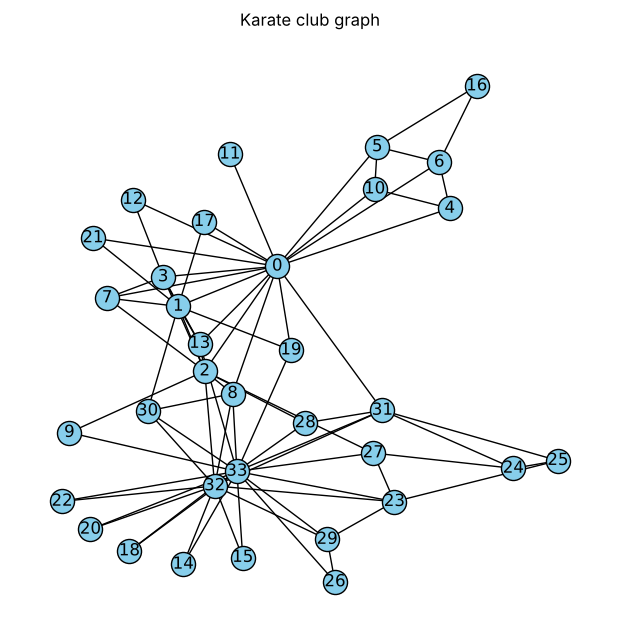

In [3]:
plt.figure(figsize=(6, 6))
nx.draw(G, pos, with_labels=True, node_color="skyblue", edgecolors="black")
plt.title("Karate club graph")
plt.show()

In [4]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)

# quick checks: B is symmetric and every row sums to 0
print(np.allclose(B, B.T), np.allclose(B.sum(axis=1), 0))

True True


## 4. Splitting a group

In [5]:
tol = 1e-8

def split_group(group):
    # block of B for this group
    Bc = B[np.ix_(group, group)]
    values, vectors = np.linalg.eigh(Bc)
    top_value = values[-1]
    top_vector = vectors[:, -1]

    if top_value <= tol:
        return None

    g1 = [group[i] for i in range(len(group)) if top_vector[i] > 0]
    g2 = [group[i] for i in range(len(group)) if top_vector[i] <= 0]
    if len(g1) == 0 or len(g2) == 0:
        return None

    # gain in modularity is s^T B s / 4m, so it must be positive
    s = np.where(top_vector > 0, 1, -1)
    if s @ Bc @ s <= tol:
        return None

    return g1, g2, top_value


def modularity_of(groups):
    return sum(B[np.ix_(g, g)].sum() for g in groups) / (2 * m)

### First split

The first split of the whole graph, drawn by the sign of the leading eigenvector (red and blue).

In [6]:
first = split_group(nodes)
print("group 1:", first[0])
print("group 2:", first[1])
print("largest eigenvalue:", round(first[2], 3))

# compare with the real split
side_a = first[0] if len(set(first[0]) & set(hi_group)) > len(set(first[1]) & set(hi_group)) else first[1]
side_b = [v for v in nodes if v not in side_a]
wrong = sorted(set(side_a) - set(hi_group)) + sorted(set(side_b) & set(hi_group))
print("members matching the real split:", n - len(wrong), "out of", n)
print("wrong side:", wrong)

group 1: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
group 2: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
largest eigenvalue: 4.977
members matching the real split: 33 out of 34
wrong side: [8]


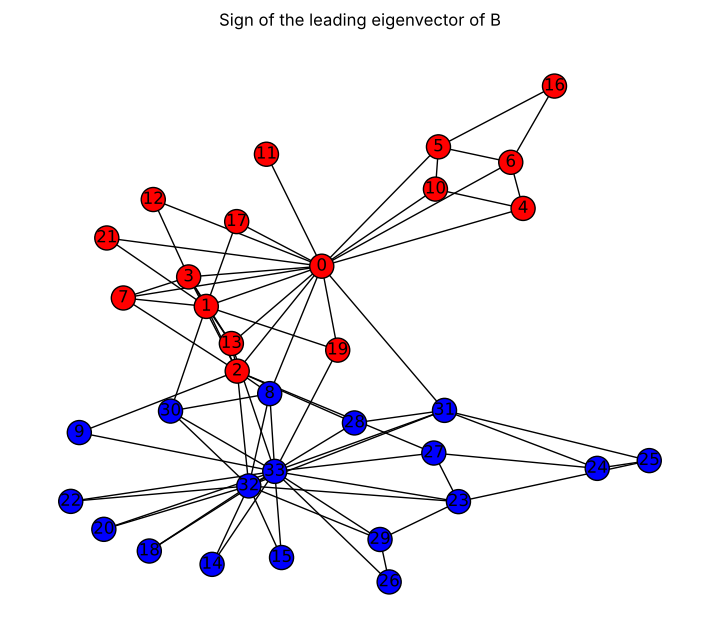

In [7]:
colors = ["red" if v in first[0] else "blue" for v in nodes]
plt.figure(figsize=(7, 6))
nx.draw(G, pos, with_labels=True, node_color=colors, edgecolors="black")
plt.title("Sign of the leading eigenvector of B")
plt.show()

## 5. Recursive splitting

Groups are taken one at a time from a queue. Every time a group is split, the list of communities is saved in `history` so that it can be drawn and the metrics can be found for each split.

In [8]:
todo = [list(range(n))]     # groups still to be checked
done = []                   # groups that cannot be split
colour_id = {tuple(todo[0]): 0}   # one colour per group, a half keeps the colour of its parent
next_colour = 1

def snapshot():
    groups = sorted([sorted(g) for g in done + todo], key=lambda g: g[0])
    cols = [colour_id[tuple(g)] for g in groups]
    return groups, cols

history = [snapshot()]
q_values = [modularity_of(history[0][0])]
split_info = []

while todo:
    group = todo.pop(0)
    result = split_group(group)
    if result is None:
        done.append(group)
        continue
    g1, g2, lam = result
    colour_id[tuple(sorted(g1))] = colour_id[tuple(sorted(group))]
    colour_id[tuple(sorted(g2))] = next_colour
    next_colour += 1
    todo.extend([g1, g2])

    groups, cols = snapshot()
    history.append((groups, cols))
    q_values.append(modularity_of(groups))
    split_info.append((len(group), len(g1), len(g2), lam))

final = history[-1][0]
print("Splits =", len(history) - 1)
print("No. of communities =", len(final))
for i, (size, a, b, lam) in enumerate(split_info, start=1):
    print(f"split {i}: group of {size} into {a} and {b}, eigenvalue {lam:.3f}, Q = {q_values[i]:.4f}")
print()
for i, g in enumerate(final, start=1):
    print(f"community {i} (size {len(g)}):", g)

Splits = 4
No. of communities = 5
split 1: group of 34 into 16 and 18, eigenvalue 4.977, Q = 0.3715
split 2: group of 16 into 10 and 6, eigenvalue 2.944, Q = 0.3898
split 3: group of 18 into 5 and 13, eigenvalue 2.504, Q = 0.4081
split 4: group of 6 into 1 and 5, eigenvalue 2.148, Q = 0.4094

community 1 (size 10): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
community 2 (size 5): [4, 5, 6, 10, 16]
community 3 (size 13): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
community 4 (size 1): [11]
community 5 (size 5): [24, 25, 27, 28, 31]


## 6. Graph after each split

Every community has its own colour and the colour of a group is kept when it splits, so the groups can be followed from one plot to the next. Dashed grey lines are the edges between different communities. Nodes with a black border belong to Mr. Hi's real group.

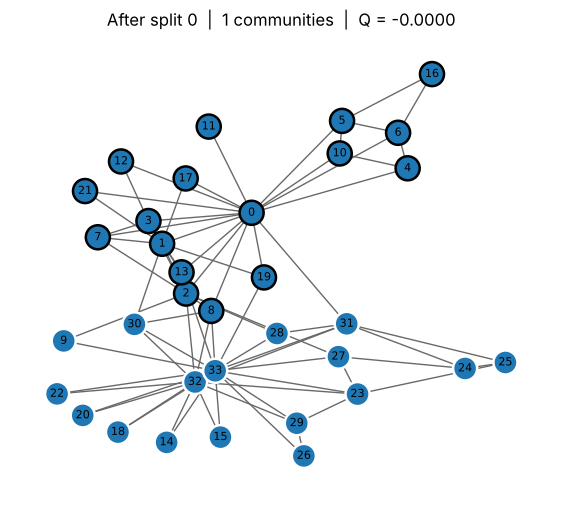

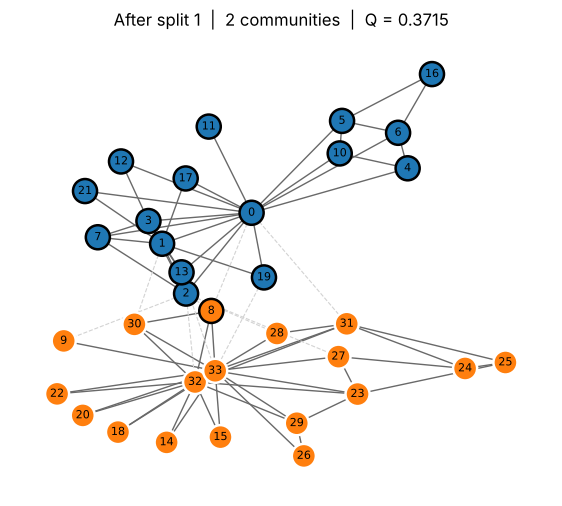

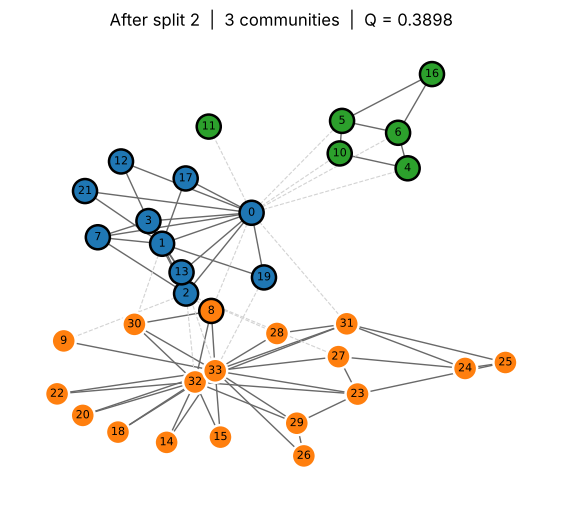

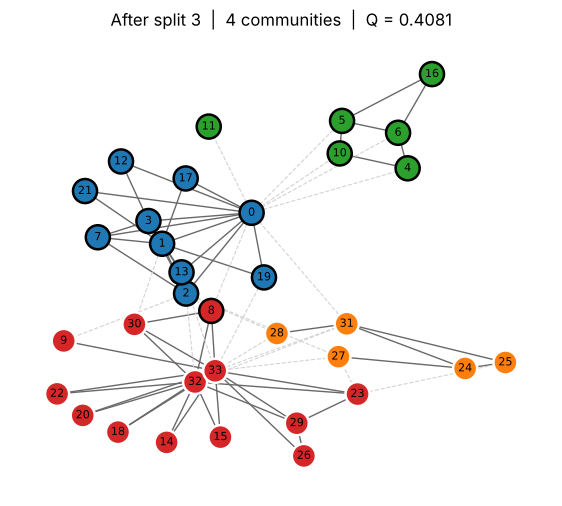

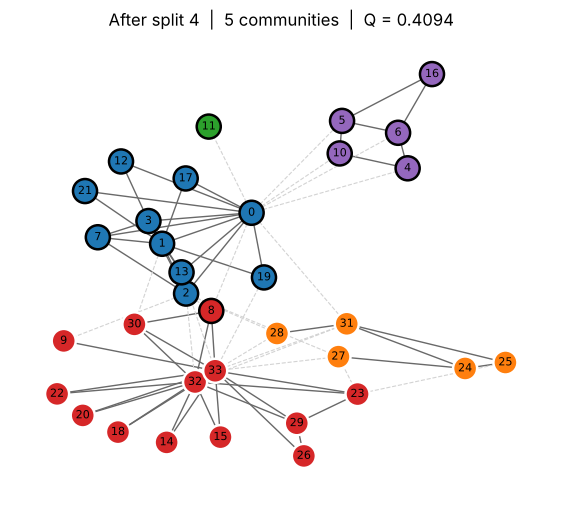

In [9]:
shades = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple",
          "tab:brown", "tab:pink", "tab:olive", "tab:cyan", "gold"]

def draw_communities(groups, cols, title):
    which = {v: i for i, g in enumerate(groups) for v in g}
    colour_of = {v: shades[cols[which[v]] % len(shades)] for v in nodes}
    inside = [e for e in G.edges() if which[e[0]] == which[e[1]]]
    across = [e for e in G.edges() if which[e[0]] != which[e[1]]]

    plt.figure(figsize=(7, 6))
    nx.draw_networkx_edges(G, pos, edgelist=inside, edge_color="dimgray")
    nx.draw_networkx_edges(G, pos, edgelist=across, edge_color="lightgray", style="dashed", width=0.8)
    nx.draw_networkx_nodes(G, pos, node_color=[colour_of[v] for v in nodes],
                           edgecolors=["black" if v in hi_group else "white" for v in nodes],
                           linewidths=1.8, node_size=300)
    nx.draw_networkx_labels(G, pos, font_size=8)
    plt.title(title)
    plt.axis("off")
    plt.show()

for step, (groups, cols) in enumerate(history):
    draw_communities(groups, cols,
                     f"After split {step}  |  {len(groups)} communities  |  Q = {q_values[step]:.4f}")

### Modularity after each split

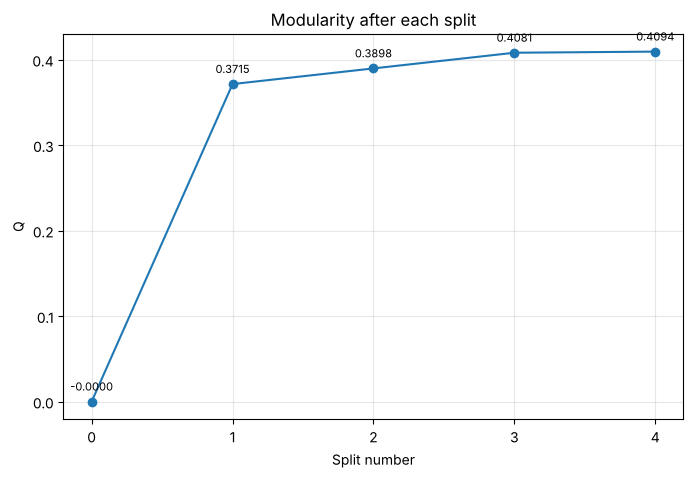

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(range(len(q_values)), q_values, marker="o", color="tab:blue")
for i, q in enumerate(q_values):
    plt.annotate(f"{q:.4f}", (i, q), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.title("Modularity after each split")
plt.xlabel("Split number")
plt.ylabel("Q")
plt.xticks(range(len(q_values)))
plt.grid(alpha=0.3)
plt.show()

## 7. Node metrics after each split

In [11]:
def cut_graph(groups):
    # same nodes, but only the edges inside communities are kept
    H = nx.Graph()
    H.add_nodes_from(nodes)
    for g in groups:
        H.add_edges_from(G.subgraph(g).edges())
    return H

graphs = [cut_graph(groups) for groups, cols in history]

def metric_table(func):
    # rows = split number, columns = node
    rows = []
    for H in graphs:
        d = func(H)
        rows.append([d[v] for v in nodes])
    return np.array(rows)

degree_t = metric_table(nx.degree_centrality)
betweenness_t = metric_table(nx.betweenness_centrality)
closeness_t = metric_table(nx.closeness_centrality)
clustering_t = metric_table(nx.clustering)

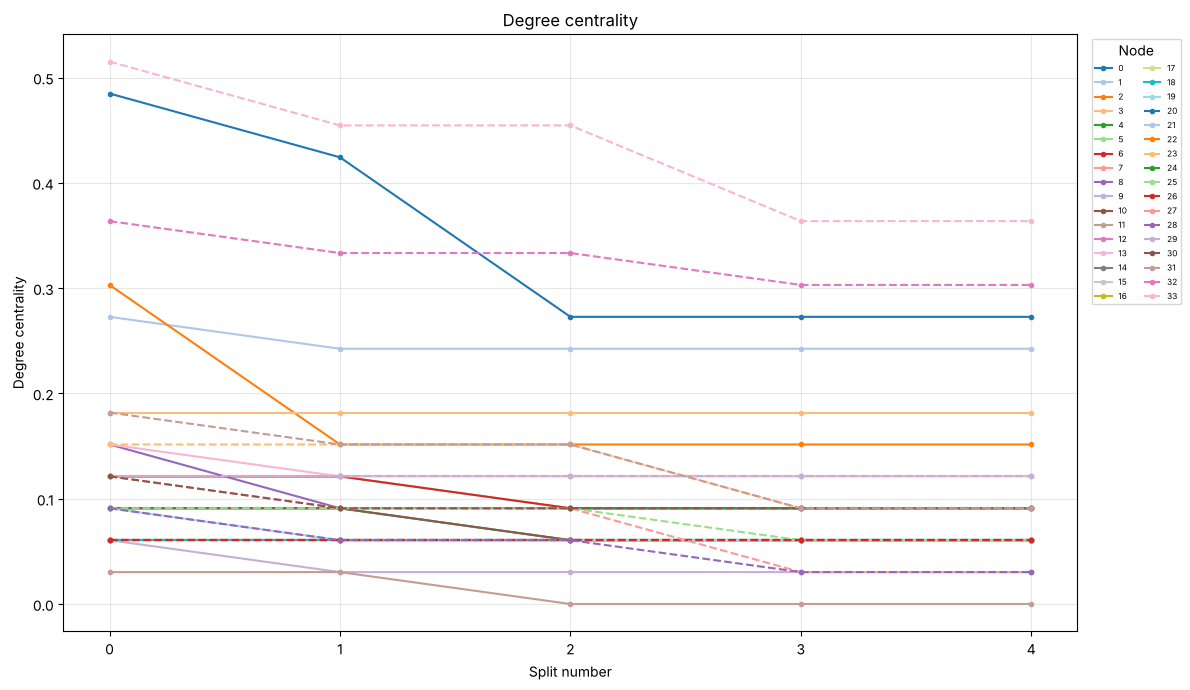

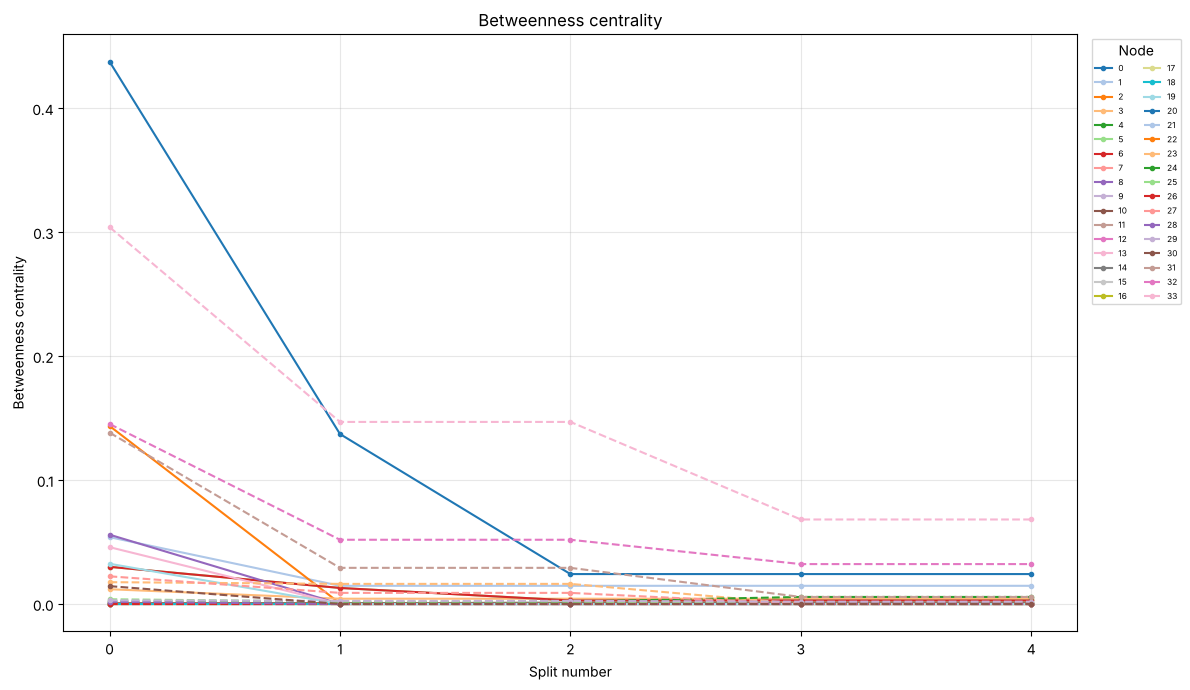

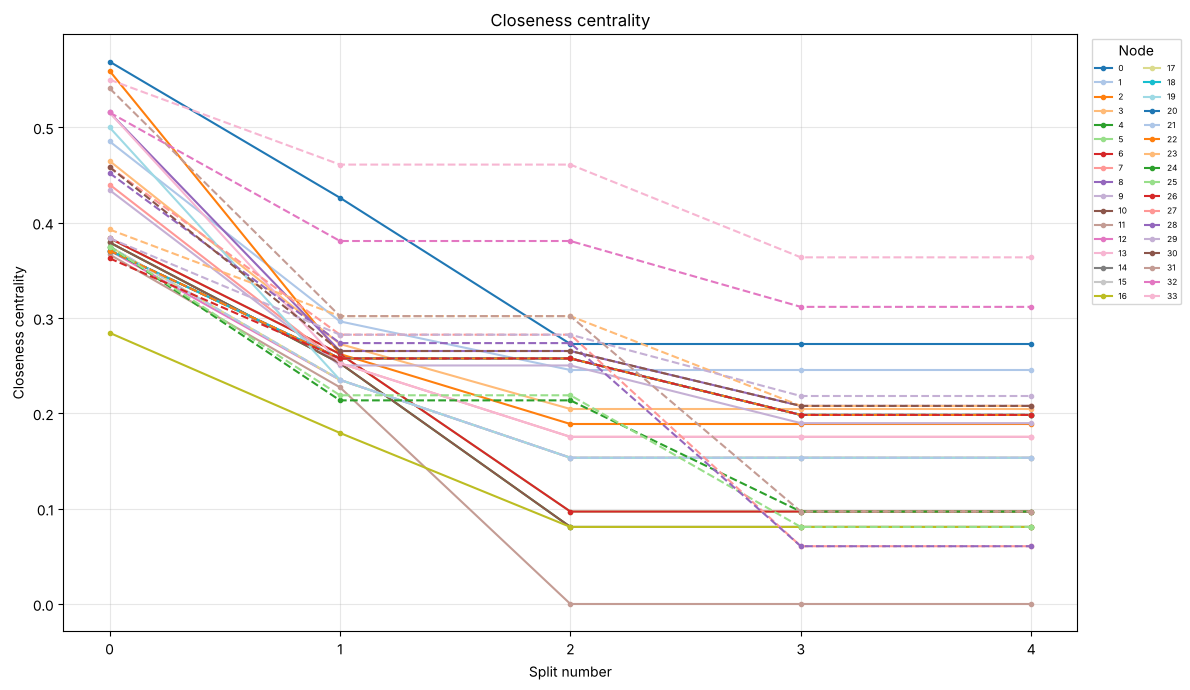

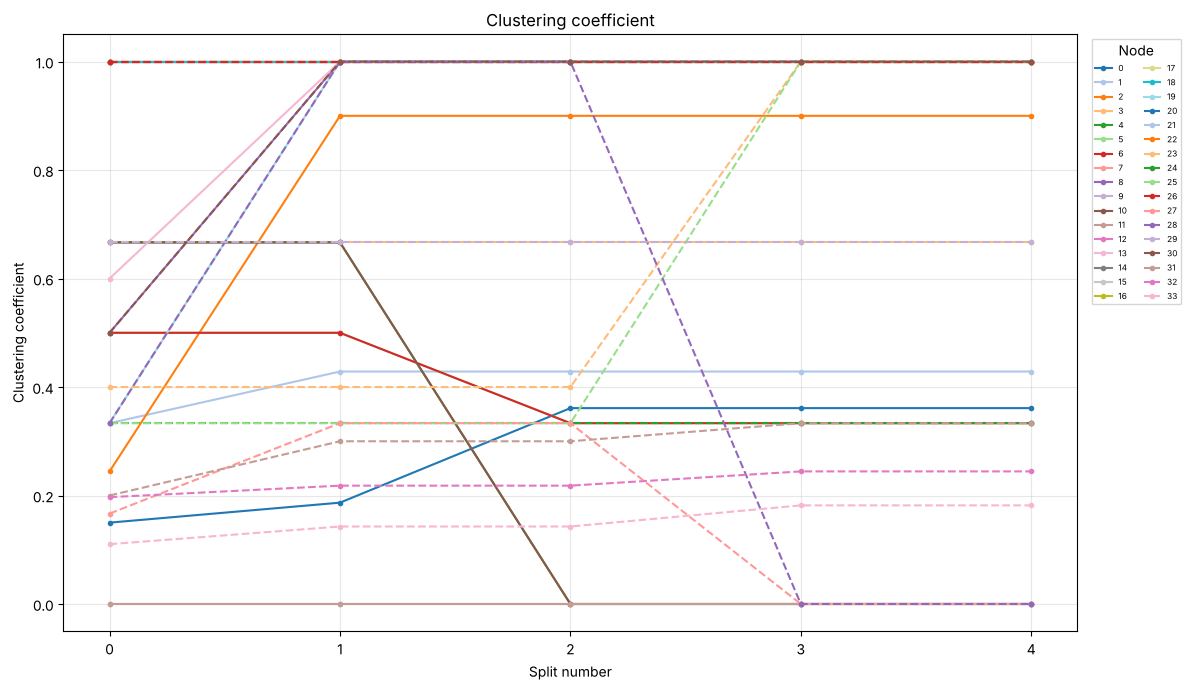

In [12]:
def plot_metric(table, name):
    plt.figure(figsize=(12, 7))
    for v in nodes:
        style = "-" if v < 20 else "--"
        plt.plot(range(len(table)), table[:, v], style, marker="o", markersize=3,
                 color=plt.cm.tab20(v % 20), label=str(v))
    plt.title(name)
    plt.xlabel("Split number")
    plt.ylabel(name)
    plt.xticks(range(len(table)))
    plt.grid(alpha=0.3)
    plt.legend(title="Node", ncol=2, fontsize=6, loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.show()

plot_metric(degree_t, "Degree centrality")
plot_metric(betweenness_t, "Betweenness centrality")
plot_metric(closeness_t, "Closeness centrality")
plot_metric(clustering_t, "Clustering coefficient")

### Most central nodes

Top 5 nodes for each metric by average value over all splits, and the nodes that are in the top 5 after every single split.

In [13]:
tables = {"Degree": degree_t, "Betweenness": betweenness_t,
          "Closeness": closeness_t, "Clustering": clustering_t}

rows = []
for name, t in tables.items():
    top_avg = [int(v) for v in np.argsort(-t.mean(axis=0))[:5]]
    always = set(np.argsort(-t[0], kind="stable")[:5])
    for row in t:
        always &= set(np.argsort(-row, kind="stable")[:5])
    rows.append([name, top_avg, sorted(int(v) for v in always),
                 round(t[0].mean(), 3), round(t[-1].mean(), 3)])

print(pd.DataFrame(rows, columns=["Metric", "Top 5 (average)", "Top 5 at every split",
                                  "Mean at split 0", "Mean at last split"]).to_string(index=False))

     Metric     Top 5 (average) Top 5 at every split  Mean at split 0  Mean at last split
     Degree   [33, 0, 32, 1, 2]       [0, 1, 32, 33]            0.139               0.102
Betweenness  [33, 0, 32, 31, 2]          [0, 32, 33]            0.044               0.005
  Closeness   [33, 32, 0, 1, 8]                 [33]            0.426               0.165
 Clustering [7, 12, 15, 14, 20]          [7, 12, 14]            0.571               0.641


## 8. Notes and discussion

Notes:

- The graph has 34 nodes and 78 edges and is treated as unweighted. The layout is fixed (seed = 42), so all plots use the same node positions.
- The method is recursive spectral bisection of the modularity matrix. A group is split only when the largest eigenvalue of its block is above 1e-8 and the gain from the split is positive.
- Result: 4 splits and 5 communities. Modularity went from 0 to 0.3715, 0.3898, 0.4081 and finally 0.4094.
- The first split gives groups of 16 and 18 members and matches the real split of the club for 33 of the 34 members. Only node 8 is on the wrong side, which is the same exception Zachary found.
- Final communities: {0, 1, 2, 3, 7, 12, 13, 17, 19, 21}, {4, 5, 6, 10, 16}, {8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33}, {24, 25, 27, 28, 31} and node 11 alone. Most of the modularity comes from the first split, the other three splits add only about 0.04 together.

Discussion:

- Nodes 33, 0 and 32 stay central through all the splits. All three are in the top 5 for degree and betweenness after every split, and node 33 is the only node that is always in the top 5 for closeness (node 1 is also always in the top 5 for degree). Their values do go down (degree of node 0 from 0.485 to 0.273, node 33 from 0.515 to 0.364), but they are the hubs of their own groups so their rank stays the same. This fits with 0 and 33 being the two leaders.
- Degree never increases. 20 nodes go down, 14 stay the same and the average goes from 0.139 to 0.102, because the edges between communities are removed.
- Betweenness changes the most. 19 nodes go down, 3 go up, 12 stay the same and the average goes from 0.044 to 0.005. Node 0 starts at 0.438 and ends at 0.024. Node 2 goes from 0.144 to 0 after the first split, which suggests it was mostly connecting the two factions.
- Closeness goes down for all 34 nodes (average 0.426 to 0.165). Node 11 falls from 0.367 to 0 when it ends up alone. Nodes 2 and 31 are in the top 4 for closeness at the start (0.559 and 0.541) but drop to 0.189 and 0.097, so they were central because of links between the groups, not inside one.
- Clustering moves the other way. 12 nodes go up, 16 stay the same, 6 go down and the average rises from 0.571 to 0.641. When the links to the other group are cut, the neighbours that remain are more likely to know each other (node 2 goes from 0.244 to 0.900 and node 8 from 0.5 to 1.0). It drops to 0 only when a node has fewer than two neighbours left, like nodes 4 and 10. Nodes 7, 12 and 14 are in the top 5 at every split because they sit in small cliques.
- So a node that is important in the whole network can look different inside its community. Hubs keep their place after splitting, while nodes that mainly act as bridges between groups lose theirs.
- Rounding the eigenvector by sign is only an approximation of the best split, and this is why node 8 ends up on the wrong side. Also, the metric values depend on the choice made in the method section to compute them on the graph without the edges between communities.
- Overall, the spectral method recovered the real split of the club from the friendship ties alone, with one member on the wrong side, and then divided the club further into 5 communities.

## 9. References

1. M. E. J. Newman, "Modularity and community structure in networks," Proceedings of the National Academy of Sciences, vol. 103, no. 23, pp. 8577-8582, 2006.
2. W. W. Zachary, "An information flow model for conflict and fission in small groups," Journal of Anthropological Research, vol. 33, no. 4, pp. 452-473, 1977.